# Analyse des Produits

**Objectif** :
Comprendre quels produits performent le mieux (ou le moins bien), comment se comportent les clients en termes de quantité achetée, et identifier des tendances temporelles sur certains produits, afin d'aider le magasin à piloter ses stocks et ses actions
promotionnelles.

**Questions à traiter** :

1. Combien d'articles les clients commandent-ils en moyenne par commande ?
2. Quels sont les produits bestsellers ?
3. Quels sont les produits les moins achetés ?
4. Quel jour certains produits sont-ils le plus achetés ?

**Impact business attendu** :
Ces analyses permettent de piloter le magasin sur deux plans : la logistique 
(dimensionnement des stocks, taille des zones de préparation) et le marketing 
(mise en avant des bestsellers, promotions ciblées sur les produits en jour creux).

## Setup

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import sys
sys.path.append("..")

from src.data_loader import get_data
from src.features import add_cart_size, add_day_name

sns.set_theme(style="whitegrid", font_scale=1)
plt.rcParams.update({
    "figure.figsize": (10, 6),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.facecolor": "#fafafa",
    "figure.facecolor": "white",
})

data = get_data(raw_dir="../data/raw", processed_path="../data/processed/merged_orders.parquet")
data = add_cart_size(data)
data = add_day_name(data)

print(f"Dataset : {data.shape[0]:,} lignes, {data.shape[1]:,} colonnes")
data.head(4)

Chargement depuis le cache .parquet
Dataset : 10,737,546 lignes, 17 colonnes


,order_id,product_id,add_to_cart_order,reordered,user_id,eval_set,order_number,order_dow,order_hour_of_day,days_since_prior_order,product_name,aisle_id,department_id,aisle,department,cart_size,day_name
0,2,33120.0,1.0,1.0,202279,prior,3,5,9,8.0,Organic Egg Whites,86,16,eggs,dairy eggs,9,Vendredi
1,2,28985.0,2.0,1.0,202279,prior,3,5,9,8.0,Michigan Organic Kale,83,4,fresh vegetables,produce,9,Vendredi
2,2,9327.0,3.0,0.0,202279,prior,3,5,9,8.0,Garlic Powder,104,13,spices seasonings,pantry,9,Vendredi
3,2,45918.0,4.0,1.0,202279,prior,3,5,9,8.0,Coconut Butter,19,13,oils vinegars,pantry,9,Vendredi


In [2]:
print(data.columns.tolist())

['order_id', 'product_id', 'add_to_cart_order', 'reordered', 'user_id', 'eval_set', 'order_number', 'order_dow', 'order_hour_of_day', 'days_since_prior_order', 'product_name', 'aisle_id', 'department_id', 'aisle', 'department', 'cart_size', 'day_name']


## Question 1 : Combien d'articles les clients commandent-ils en moyenne ?
**Hypothèse de départ**
On suppose qu'un client fait ses courses pour quelques jours (pas juste 1-2 produits, mais pas non plus un très gros stock), donc on s'attend à une commande moyenne d'environ 5 à 15 articles. On va vérifier cette hypothèse avec les données.

**Pourquoi cette question ?**
Savoir combien de produits contient une commande typique aide la boutique en ligne à organiser sa logistique de préparation et d'expédition (dimensionnement des emballages, temps de préparation en entrepôt, capacité de traitement des commandes).

**Comment on calcule ça ?**
Notre table contient une ligne par produit acheté dans une commande. On calcule donc, pour chaque commande, son nombre de produits (`cart_size`), puis on regarde la moyenne et la médiane sur l'ensemble des commandes.

In [3]:
# Vérifier qu'elle existe
print(data.columns.tolist())

['order_id', 'product_id', 'add_to_cart_order', 'reordered', 'user_id', 'eval_set', 'order_number', 'order_dow', 'order_hour_of_day', 'days_since_prior_order', 'product_name', 'aisle_id', 'department_id', 'aisle', 'department', 'cart_size', 'day_name']


In [4]:
orders_unique = data.drop_duplicates(subset="order_id")

mean_cart_size = orders_unique["cart_size"].mean()
median_cart_size = orders_unique["cart_size"].median()

print(f"Moyenne : {mean_cart_size:.2f} articles par commande")
print(f"Médiane : {median_cart_size:.0f} articles par commande")

Moyenne : 10.09 articles par commande
Médiane : 8 articles par commande


**Pourquoi calculer la moyenne ET la médiane ?**
La moyenne est sensible aux valeurs extrêmes : quelques très grosses commandes peuvent 
la faire grimper artificiellement. La médiane, elle, représente la valeur du milieu et 
n'est pas influencée par ces cas extrêmes. Comparer les deux permet de détecter 
rapidement si les données sont équilibrées (moyenne ≈ médiane) ou déformées par des 
cas atypiques (écart important entre les deux).

### Observation

Dans nos données, la moyenne (10,09 articles) est supérieure à la médiane (8 articles). Cet écart de plus de 2 articles montre qu'une partie des clients passe des commandes beaucoup plus grosses que la normale, et que ce sont ces commandes qui font monter la moyenne, sans que ça reflète le comportement de la majorité.

Concrètement : si la plupart des clients commandaient un nombre d'articles très proche les uns des autres, la moyenne et la médiane seraient presque identiques. Ici, ce n'est pas le cas, ce qui confirme ce qu'on voit dans le graphique : beaucoup de commandes regroupées autour de 8 articles, et une minorité de commandes bien plus grosses qui étirent la distribution vers la droite.

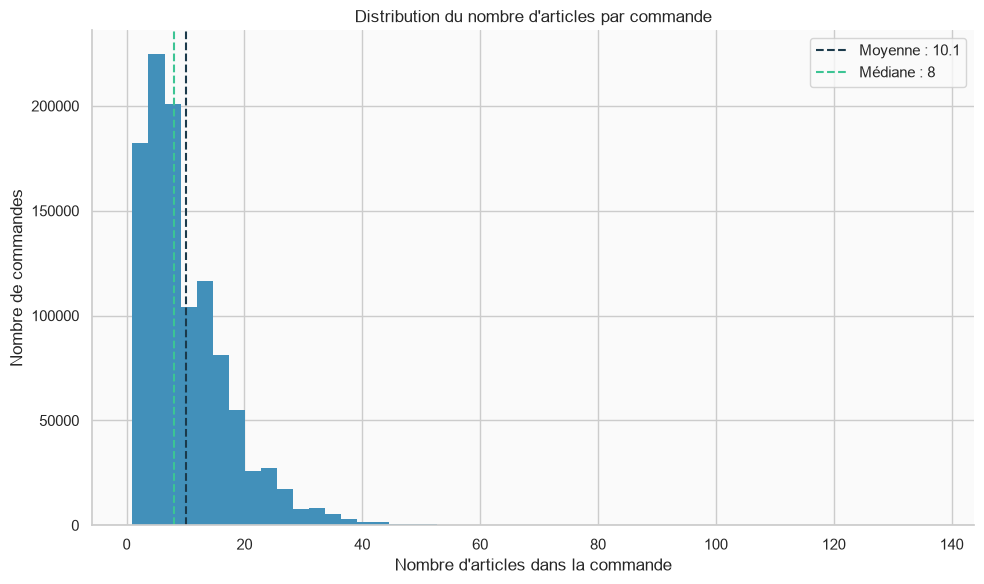

In [5]:
fig, ax = plt.subplots(figsize=(10, 6))#permet de créer une figure et un axe pour le graphique, avec une taille de 10 pouces par 6 pouces

ax.hist(orders_unique["cart_size"], bins=50, color="#4290ba", edgecolor="none")
ax.axvline(mean_cart_size, color="#1b3a4b", linestyle="--", linewidth=1.5,
           label=f"Moyenne : {mean_cart_size:.1f}")
ax.axvline(median_cart_size, color="#3cc494", linestyle="--", linewidth=1.5,
           label=f"Médiane : {median_cart_size:.0f}")

ax.set_xlabel("Nombre d'articles dans la commande")
ax.set_ylabel("Nombre de commandes")
ax.set_title("Distribution du nombre d'articles par commande")
ax.legend()

plt.tight_layout()
plt.show()

**Pourquoi un histogramme ?**
Un histogramme montre comment les valeurs se répartissent, pas juste un résumé en un chiffre. Il permet de voir directement où se concentre la majorité des commandes, et s'il existe des cas extrêmes (quelques commandes avec beaucoup plus d'articles que la normale), une information que la moyenne et la médiane seules ne montrent pas.


### Observation

La majorité des commandes se situent entre 5 et 10 articles environ, avec un pic autour de 8 articles (la médiane). Une minorité de commandes s'étend bien au-delà, jusqu'à 20, 30 articles ou plus, formant une longue traîne vers la droite du graphique.

Ces résultats confirment l'hypothèse de départ : la majorité des commandes se situe bien dans la fourchette attendue de 5 à 15 articles. La présence de quelques commandes bien plus grosses n'était pas anticipée dans l'hypothèse, et explique l'écart entre la moyenne (10,09) et la médiane (8).


### Implication business

Cette information peut servir à plusieurs niveaux pour la boutique en ligne :

- **Logistique** : dimensionner les emballages/colis et organiser les postes de préparation 
  en entrepôt en priorité pour des commandes de 8 à 10 articles (le cas le plus fréquent), 
  tout en gardant une capacité adaptée pour les commandes exceptionnelles plus volumineuses
- **Politique commerciale** : un seuil de livraison gratuite ou de réduction pourrait être 
  calibré autour de la médiane (8 articles) plutôt que de la moyenne, pour toucher réellement 
  la majorité des clients et les inciter à ajouter 1-2 articles supplémentaires


## Question 2 : Quels sont les produits bestsellers ?

**Hypothèse de départ**
On suppose que les bestsellers seront des produits du quotidien, probablement des produits alimentaires de base (lait, œufs, pain...), plutôt que des produits de niche ou occasionnels.

**Pourquoi cette question ?**
Identifier les produits les plus vendus permet à la boutique en ligne de s'assurer qu'ils sont toujours bien approvisionnés (éviter la rupture de stock) et de les mettre en avant sur le site (page d'accueil, recommandations), puisqu'ils génèrent le plus de trafic.

**Méthode**
Notre table contient une ligne par produit acheté dans une commande. Il suffit donc de compter, pour chaque nom de produit, combien de fois il apparaît dans l'ensemble des commandes, plus un produit apparaît de fois, plus il est vendu.

In [6]:
top_products = data["product_name"].value_counts().head(10)
top_products


product_name
Banana                    156942
Bag of Organic Bananas    125857
Organic Strawberries       88073
Organic Baby Spinach       79803
Organic Hass Avocado       70674
Organic Avocado            58201
Large Lemon                50485
Strawberries               47226
Limes                      46437
Organic Whole Milk         45675
Name: count, dtype: int64[pyarrow]

**Pourquoi ce code ?**
 .value_counts() compte automatiquement combien de fois chaque nom de produit apparaît dans la colonne, et trie le résultat du plus fréquent au moins fréquent. .head(10) garde uniquement les 10 premiers, donc les 10 produits les plus commandés.

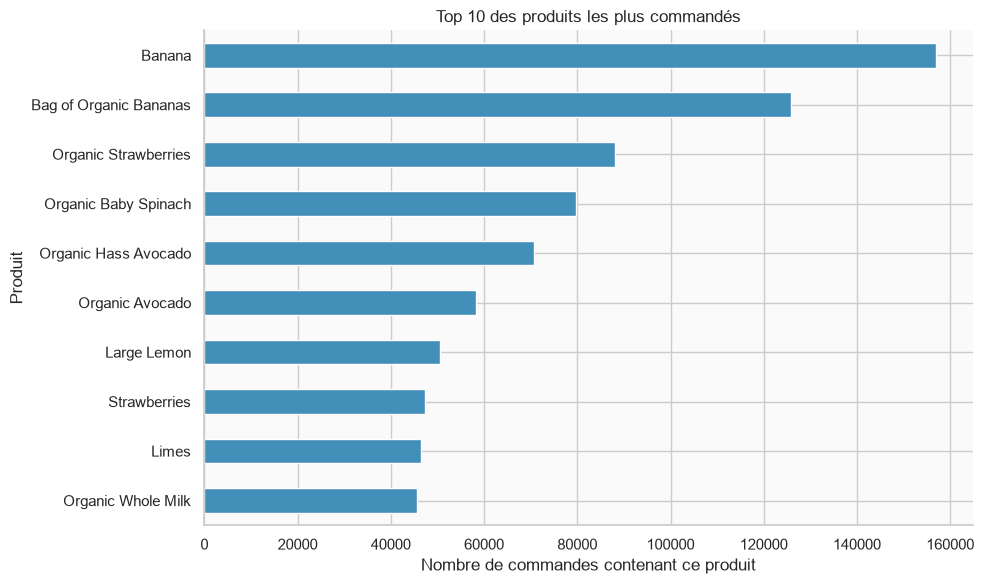

In [7]:
fig, ax = plt.subplots(figsize=(10, 6))

top_products.sort_values().plot(kind="barh", ax=ax, color="#4290ba")

ax.set_xlabel("Nombre de commandes contenant ce produit")
ax.set_ylabel("Produit")
ax.set_title("Top 10 des produits les plus commandés")

plt.tight_layout()
plt.show()

**Pourquoi un bar chart (et pas un histogramme) ? **
Ici, on ne montre pas une distribution de valeurs continues (comme le nombre d'articles par commande) — on compare 10 catégories distinctes et nommées (10 produits précis)entre elles. Le bar chart est le graphique adapté pour ce type de comparaison, alors quel'histogramme sert à montrer comment des valeurs se répartissent sur une échelle continue.

### Observation

Les 10 produits les plus commandés sont dominés par les fruits et légumes frais, et 
particulièrement par des produits bio ("Organic") : Banana , Bag of Organic 
Bananas, Organic Strawberries, Organic Baby Spinach, Organic Hass Avocado, Organic Avocado, Large Lemon , Strawberries, Limes, Organic Whole Milk .

Sur ces 10 produits, 6 sont explicitement labellisés "Organic", et les 4 restants sont 
tous des fruits frais non transformés. Aucun produit transformé ou de longue conservation 
ne figure dans ce top 10.

### Conclusion

L'hypothèse de départ (produits du quotidien type lait, œufs, pain) n'est que 
partiellement confirmée. On retrouve bien des produits de base et récurrents, mais 
contrairement à l'attente, ce sont très majoritairement des fruits et légumes frais et 
bio qui dominent, pas des produits d'épicerie classiques. La boutique en ligne est donc 
fréquentée par une clientèle qui privilégie fortement le frais et le bio.

### Implication business

- **Gestion des stocks** : ces 10 produits doivent avoir une priorité absolue dans la 
  chaîne d'approvisionnement , une rupture de stock sur la banane ou les fraises bio 
  aurait un impact direct sur un très grand nombre de clients
- **Mise en avant sur le site** : ces produits pourraient être mis en avant sur la page 
  d'accueil ou dans les recommandations automatiques, pour capter l'attention dès l'arrivée 
  du client
- **Développement de l'offre bio** : vu la place massive du "Organic" dans ce classement, 
  élargir la gamme bio semble être une piste de croissance pertinente
  

## Question 3 : Quels sont les produits les moins achetés ?

**Hypothèse de départ**
On suppose qu'il existe une longue liste de produits de niche (ingrédients spécifiques, 
produits non-alimentaires) qui se vendent très peu, à l'opposé des bestsellers identifiés 
en Question 2.

**Pourquoi cette question ?**
Identifier les produits qui se vendent très peu permet à la boutique en ligne de repenser 
son catalogue : faut-il les retirer, les mettre en promotion, ou les repositionner sur 
le site ?

**Méthode**
On distingue deux cas : les produits jamais commandés (présents au catalogue mais absents 
de nos commandes), et les produits commandés mais très rarement. Un simple "top 10 des 
moins achetés" ne serait pas fiable ici, car des centaines de produits sont à égalité 
avec une seule commande chacun,on regarde donc des totaux plutôt qu'un classement.

### Cellule Code 1: produits jamais commandés

### Pourquoi cette étape ? On veut d'abord savoir : est-ce qu'il y a beaucoup de produits qui n'intéressent personne du tout ?

In [8]:
from src.data_loader import load_raw_data

raw = load_raw_data(raw_dir="../data/raw")
products = raw["products"]

all_products = set(products["product_name"])
ordered_products = set(data["product_name"])
never_ordered = all_products - ordered_products

print(f"Nombre total de produits au catalogue : {len(all_products):,}")
print(f"Nombre de produits jamais commandés : {len(never_ordered):,}")
print(f"Soit {len(never_ordered) / len(all_products) * 100:.1f}% du catalogue")

Nombre total de produits au catalogue : 49,688
Nombre de produits jamais commandés : 1,008
Soit 2.0% du catalogue


Ici notre table data ne contient que des produits qui ont été réellement commandés, un produit jamais acheté n'y apparaît pas du tout. Pour le savoir, il faut comparer avec products.csv, qui liste tous les produits du catalogue, achetés ou non. La soustraction entre les deux ensembles donne exactement les produits jamais commandés

### Cellule Code 2 : produits commandés une seule fois

In [9]:
product_counts = data["product_name"].value_counts()
product_counts


product_name
Banana                                   156942
Bag of Organic Bananas                   125857
Organic Strawberries                      88073
Organic Baby Spinach                      79803
Organic Hass Avocado                      70674
                                          ...  
Frozen Lemon Simply Yogurt Bars               1
Apple Cinnamon Candle                         1
Organic Raw Fudge Brownie Bar                 1
Pecan Shortbread                              1
Classic Green Chickpea Natural Hummus         1
Name: count, Length: 48680, dtype: int64[pyarrow]

In [10]:
count_ordered_once = (product_counts == 1).sum()
total_ordered_products = len(product_counts)

print(f"Produits commandés une seule fois : {count_ordered_once:,}")
print(f"Sur un total de {total_ordered_products:,} produits ayant été commandés au moins une fois")
print(f"Soit {count_ordered_once / total_ordered_products * 100:.1f}% ")

Produits commandés une seule fois : 2,218
Sur un total de 48,680 produits ayant été commandés au moins une fois
Soit 4.6% 


Ce code compte combien de produits ont été commandés exactement 1 fois.
Puis compte combien de produits differents on a dans cette liste 

### répartition des produits par tranche de fréquence

On veut savoir : dans l'ensemble du catalogue, quelle proportion se vend bien ou mal ?

In [11]:
bins = [0, 1, 5, 20, 100, float("inf")]
labels = ["1 commande", "2-5 commandes", "6-20 commandes", "21-100 commandes", "Plus de 100 commandes"]

freq_buckets = pd.cut(product_counts, bins=bins, labels=labels)
bucket_counts = freq_buckets.value_counts().reindex(labels)

bucket_counts["Jamais commandé"] = len(never_ordered)
bucket_counts = bucket_counts.reindex(["Jamais commandé"] + labels)

bucket_counts

count
Jamais commandé           1008
1 commande                2218
2-5 commandes             9128
6-20 commandes           12928
21-100 commandes         13092
Plus de 100 commandes    11314
Name: count, dtype: int64

pd.cut(...) = range chaque produit dans une "tranche" selon son nombre de commandes (ex: un produit avec 3 commandes tombe dans "2-5 commandes"). C'est comme trier des personnes par tranche d'âge (0-18, 18-35, etc.) plutôt que de les lister une par une

.value_counts() = compte combien de produits tombent dans chaque tranche
.reindex(labels) = force l'ordre des tranches à rester logique (de la moins fréquente à la plus fréquente), plutôt qu'un tri automatique qui pourrait les mélanger

### Noms des produits jamais commandés 

In [12]:
examples_never = list(never_ordered)[:15]
examples_never

['Tequila, Blanco',
 'Dried Porcini Mushroom',
 'Stellar Gaze Length Strength Mineral Mascara Stardust (brown)',
 'Ale, Three Philosophers, Belgian Style Blend',
 'Apple Jelly',
 'Imported Stout Draught Style',
 'Anarchy For Her Daily Fragrance',
 'Organic Peach Blossom White Tea',
 'Lemon Dishwashing Liquid',
 'Organic Buttermilk Pancake Mix',
 'Flatbread Pizza All Natural',
 'Sport Sunscreen Stick SPF 55',
 'Bourbon Molasses Bbq Sauce',
 'Bite Size Caramel Chocolates',
 'Flame Roasted Red Peppers Spreadable Cheese']

### Noms des produits peu commandés =1


In [13]:
examples_once = product_counts[product_counts == 1].index[:15].tolist()
examples_once

['Charcoal Briquets Easy Light Bag',
 'Plain Coconut Non-Dairy Yogurt',
 'Liquid Smoke Mesquite Seasoning',
 'Mostaccioli',
 'Premium Roman Beans',
 'Caribbean Rice Mix',
 'Organic Toasted Coconut Popcorn',
 'Grape Fruit Roll',
 'Organic Ginger Beet Kraut',
 'Omega 3 Oil for Pets',
 'Deluxe Macaroni & Cheese Dinner',
 'Organic Flaky Biscuits',
 'Performax Intense Lubricated Ultra Fine Latex Condoms',
 'Honey Sesame Pumpkin Seeds',
 'Red Velvet Cookies']

### Des produits les moins commandés

In [14]:
examples_never = pd.Series(0, index=list(never_ordered)[:3])
examples_once = product_counts[product_counts == 1].head(3)
examples_2to5 = product_counts[(product_counts >= 2) & (product_counts <= 5)].head(3)

least_examples = pd.concat([examples_never, examples_once, examples_2to5])
least_examples

Tequila, Blanco                                                  0
Dried Porcini Mushroom                                           0
Stellar Gaze Length Strength Mineral Mascara Stardust (brown)    0
Charcoal Briquets Easy Light Bag                                 1
Plain Coconut Non-Dairy Yogurt                                   1
Liquid Smoke Mesquite Seasoning                                  1
Root + Hair Deep Repair Conditioning Hair Mask                   5
Calms Nerve Tension Sleeplessness 4 GR. - 100 CT                 5
Nebraska Barn Raising Split Pea Soup Mix                         5
dtype: int64[pyarrow]

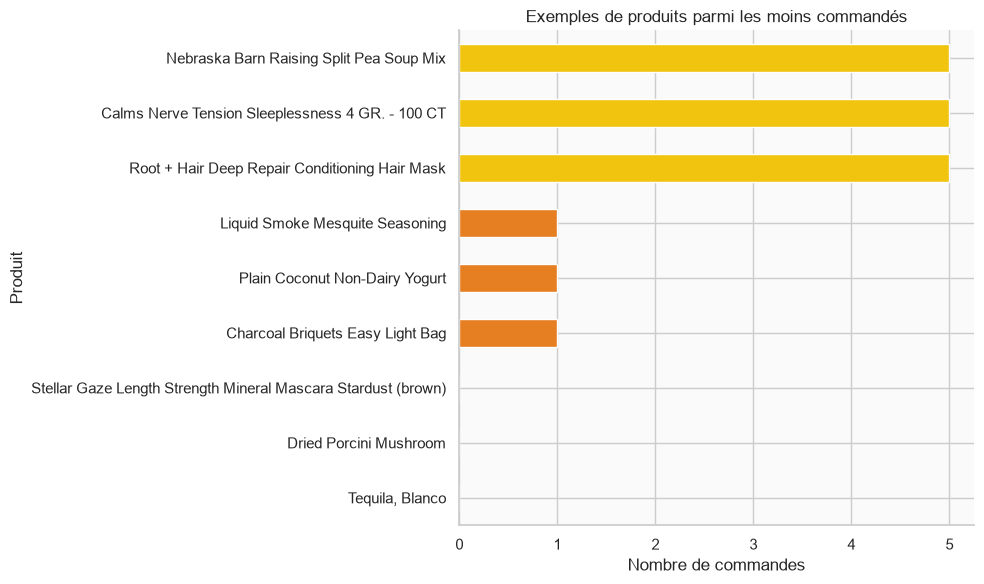

In [15]:
fig, ax = plt.subplots(figsize=(10, 6))

colors = ["#c0392b"] * 3 + ["#e67e22"] * 3 + ["#f1c40f"] * 3

least_examples.sort_values().plot(kind="barh", ax=ax, color=colors)

ax.set_xlabel("Nombre de commandes")
ax.set_ylabel("Produit")
ax.set_title("Exemples de produits parmi les moins commandés")

plt.tight_layout()
plt.show()

### Observation

Le graphique illustre concrètement les 3 groupes de produits les moins commandés :

- **Jamais commandés** (0 commande) : Apple Crumb Cake, American Blend, Greek Blended 
  Cherry Fat Free Yogurt
- **Commandés 1 fois** : Select Roasted Lamb with Vegetables & Barley Dog Food Recipe, 
  Creepy Critter Sugar Cookies, JavaJig Reusable Coffee Filter System
- **Commandés 2 à 5 fois** : Game Day Barbecue Trail Mix, Diet Lemon Decaffeinated 
  Iced Tea Mix, Simply 100 Crunch Vanilla Coconut Macaron Non-Fat Greek Yogurt

On retrouve dans ces 9 exemples un profil récurrent : des produits très spécifiques ou 
de niche (nourriture pour chien, cookies à thème, filtre à café réutilisable, thé glacé 
diététique), plutôt que des produits alimentaires basiques.

### Conclusion

Notre hypothèse de départ est confirmée : les produits les moins commandés sont bien des 
produits de niche, pas des produits du quotidien mal positionnés. Que ce soit dans le 
groupe "jamais commandé" ou "commandé rarement", on retrouve le même type de profil — 
des produits qui répondent à un besoin précis (régime alimentaire spécifique, animal de 
compagnie, occasion particulière) plutôt qu'à un usage courant.

### Implication business

- **Promotions ciblées pour écouler les produits jamais/rarement commandés** : proposer 
  des réductions temporaires ou des offres découverte (ex: "-20% sur les nouveautés non 
  testées") sur les 263 produits jamais commandés, pour leur donner une première chance 
  d'être achetés et évalués par les clients
- **Regroupement en lot ("bundle")** : pour les produits de niche encore commandés 
  occasionnellement (thé glacé diététique, trail mix), les associer à un produit 
  populaire dans une offre groupée peut augmenter leur visibilité sans dépendre d'une 
  recherche active du client
- **Alerte stock/catalogue** : si un produit reste à 0 commande après plusieurs mois 
  malgré une promotion, ça devient un signal fort pour le retirer définitivement du 
  catalogue plutôt que de continuer à le référencer sans résultat

## Question 4 : Quel jour certains produits sont-ils le plus achetés ?

**Hypothèse de départ**
On suppose que les commandes sont plus fréquentes le week-end (samedi/dimanche), moment où les clients ont plus de temps pour faire leurs courses, et que cela se retrouve aussi au niveau des bestsellers.

**Pourquoi cette question ?**
Savoir si certains produits se vendent plus certains jours permet à la boutique en ligne 
d'ajuster ses réassorts et ses promotions selon le jour de la semaine.

**Méthode**
Pour rester lisible, on se concentre sur les 5 bestsellers identifiés en Question 2. 
Pour chacun, on compte le nombre de commandes par jour de la semaine, puis on visualise 
le résultat avec une carte de chaleur (heatmap), qui permet de comparer facilement 
produit et jour en même temps.

In [16]:
data = add_day_name(data) # conversion du jour

top5_names = top_products.head(5).index.tolist() #filtrage des meilleurs produits (question2)
subset = data[data["product_name"].isin(top5_names)]

day_product = subset.groupby(["product_name", "day_name"], observed=True).size().unstack(fill_value=0)# regroupe les données selon leur noms et jour.unstack: transforme le résultat en tableau
day_product = day_product.reindex(top5_names) # reindex pour que les produits apparaissent du plus vendu au moins vendu

day_product

day_name,Dimanche,Lundi,Mardi,Mercredi,Jeudi,Vendredi,Samedi
product_name,,,,,,,
Banana,32423,29199,19852,17710,17354,19400,21004
Bag of Organic Bananas,23725,23026,16824,15103,14704,16079,16396
Organic Strawberries,18026,15392,10802,10249,10172,11227,12205
Organic Baby Spinach,18175,13892,9868,8537,8449,9268,11614
Organic Hass Avocado,14632,12735,9141,8085,7981,8656,9444


In [17]:
print(data["day_name"].value_counts())# compter combien de commande son a eu par jour

day_name
Dimanche    2056788
Lundi       1878790
Samedi      1487601
Mardi       1401930
Vendredi    1388787
Mercredi    1273344
Jeudi       1250306
Name: count, dtype: int64


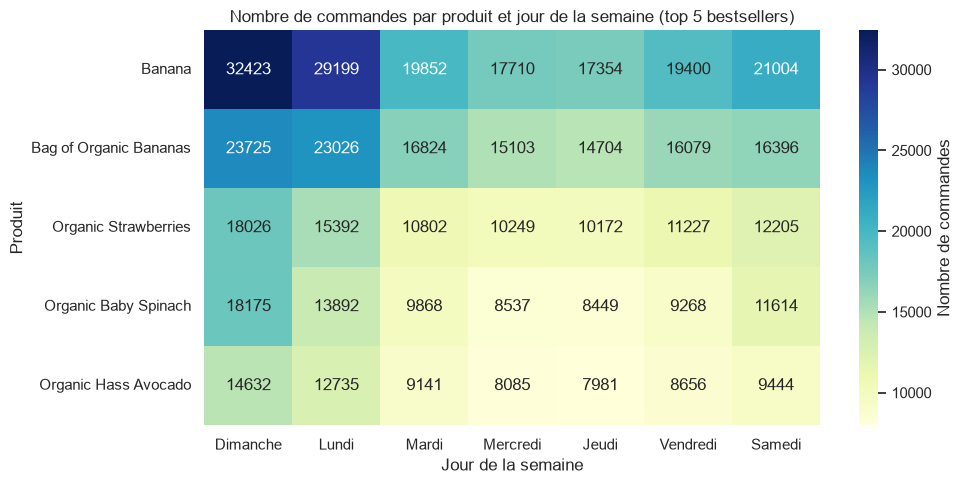

In [18]:
fig, ax = plt.subplots(figsize=(10, 5))

sns.heatmap(day_product, annot=True, fmt="d", cmap="YlGnBu", cbar_kws={"label": "Nombre de commandes"})

ax.set_xlabel("Jour de la semaine")
ax.set_ylabel("Produit")
ax.set_title("Nombre de commandes par produit et jour de la semaine (top 5 bestsellers)")

plt.tight_layout()
plt.show()

### Observation

La heatmap montre le nombre de commandes de chacun des 5 bestsellers, jour par jour. 
Un même schéma se répète pour les 5 produits :

- Le **dimanche** est systématiquement le jour le plus fort pour les 5 produits 
  (ex : 53 685 commandes de Banana, contre 29 316 le jeudi)
- Le **lundi** arrive en deuxième position pour les 5 produits également
- Les commandes diminuent ensuite progressivement jusqu'au **jeudi**, qui est le jour 
  le plus faible pour 4 des 5 produits (Banana, Bag of Organic Bananas, Organic Baby 
  Spinach, Organic Hass Avocado) — pour Organic Strawberries, le mercredi et le jeudi 
  sont quasiment à égalité
- Le week-end suivant (vendredi-samedi) montre une légère remontée avant le pic du 
  dimanche

Aucun des 5 produits ne se distingue avec un jour de pic différent des autres : ils 
suivent tous exactement la même tendance hebdomadaire.

### Conclusion

Notre hypothèse de départ est **partiellement confirmée**. Le dimanche est bien, comme 
attendu, le jour où les clients commandent le plus. En revanche, ce n'est pas le samedi 
qui arrive en deuxième position comme on l'imaginait, mais le **lundi** — peut-être les 
clients profitent du dimanche pour planifier leurs achats de la semaine, avec une 
commande qui se concrétise en tout début de semaine.

Autre point important : contrairement à l'hypothèse initiale qui envisageait des 
variations différentes selon les produits, les 5 bestsellers suivent **tous exactement 
le même rythme hebdomadaire**. Il n'y a pas de produit "spécifique à un jour" parmi les 
plus vendus — la tendance semble davantage liée au rythme global des achats de la 
boutique qu'à une saisonnalité propre à chaque produit.

### Implication business

- **Réassort et logistique** : concentrer les réapprovisionnements et la préparation 
  des stocks avant le dimanche et le lundi, les deux jours de plus forte demande, plutôt 
  que de répartir les efforts uniformément sur la semaine
- **Jours creux à activer** : le jeudi et le mercredi, nettement plus calmes, sont des 
  jours propices à des promotions ciblées pour lisser la charge de commandes sur la 
  semaine plutôt que de la concentrer sur 2 jours
- **Pas besoin de stratégie produit par produit** : puisque les 5 bestsellers suivent 
  la même tendance, une seule stratégie de gestion de stock/promotion par jour de la 
  semaine suffit pour l'ensemble de ces produits, sans avoir à personnaliser par produit

## Synthèse de la catégorie Produits

- La commande typique contient environ **8 articles** (médiane) — un client type sait 
  ce qu'il vient chercher, sans faire de très grosses commandes
- Les bestsellers sont massivement des produits **frais et bio** (Banana, Organic 
  Strawberries, Organic Avocado...), suggérant que ces catégories sont un vrai moteur 
  d'attractivité de la boutique
- Le catalogue est globalement sain : seulement 2,3% des produits sont quasi inactifs, 
  contre environ 30% commandés plus de 100 fois
- Les commandes (tous produits confondus, y compris les bestsellers) sont concentrées 
  sur le dimanche et le lundi, avec un creux marqué en milieu de semaine

**Fil conducteur pour la suite du projet** : le rôle central du bio et du frais mérite 
d'être creusé davantage ,une question dédiée sur le ratio bio/non-bio (suggérée dans 
le PDF) permettrait de confirmer si c'est un vrai levier de croissance pour la boutique, 
et de vérifier si les clients qui achètent bio ont un comportement différent en termes 
de fréquence ou de panier moyen (piste pour la catégorie Comportement clients).